# Fireline: analysis

This is where the project started: exploring free satellite data for the July 2024 Jasper wildfire, working out what can be measured reliably, and checking the results against official records. The web app came after, and the scripts in `pipeline/` are the cleaned-up versions of the steps worked out here

**Question:** using only free satellite data, can we map how much of the Jasper valley burned, how fast it happened, and how close the fire came to buildings in town?


The notebook is self-contained. The first run downloads about 750 MB into `data_raw/` (git-ignored) and takes 10 to 15 minutes, after that everything loads from disk. Install the libraries with `pip install -r requirements.txt`

<br/>
<br/>

### 1. Finding usable satellite passes

The study area is a box around the Athabasca valley, from Pyramid Mountain north of Jasper to Athabasca Falls in the south, about 43 x 46 km. Window: late May to October 2024, around the fire on 22 to 24 July

In [52]:
import plotly.graph_objects as go

AOI = (-118.30, 52.57, -117.66, 52.99)   # Area of Interest: west, south, east, north
west, south, east, north = AOI
JASPER = (-118.0824, 52.8752)            # townsite (lon, lat)

# satellite basemap with the study area drawn on top
fig = go.Figure(go.Scattermap(lon=[west, east, east, west, west], lat=[south, south, north, north, south],
                              mode="lines", line=dict(color="red", width=2), name="study area"))
fig.add_trace(go.Scattermap(lon=[JASPER[0]], lat=[JASPER[1]], mode="markers+text", text=["Jasper"],
                            textposition="top right", marker=dict(size=9, color="white"), textfont=dict(color="white")))
fig.update_layout(
    map=dict(style="white-bg", center=dict(lon=(west + east) / 2, lat=(south + north) / 2), zoom=8.6,
             layers=[dict(below="traces", sourcetype="raster", sourceattribution="Esri World Imagery",
                          source=["https://server.arcgisonline.com/ArcGIS/rest/services/World_Imagery/MapServer/tile/{z}/{y}/{x}"])]),
    height=500, margin=dict(l=0, r=0, t=0, b=0), showlegend=False)
fig.show()

<br/>

**Sentinel-2** is a pair of European satellites that photograph the same spot every 2 to 5 days at 10 to 20 m resolution. **Level-2A** is the version corrected for the atmosphere, so values are surface reflectance and comparable from one date to the next ([Sentinel-2 L2A](https://registry.opendata.aws/sentinel-2-l2a-cogs/))

[Earth Search](https://element84.com/earth-search/) is a **STAC** catalogue (SpatioTemporal Asset Catalog), a standard way to search imagery by area, date and properties. The search below asks for every pass that touches our box, with less than 60% cloud over the whole tile

In [53]:
import pandas as pd
from pystac_client import Client

START, END = "2024-05-25", "2024-10-20"

# search the Sentinel-2 archive for every pass over the box in the window
stac = Client.open("https://earth-search.aws.element84.com/v1")
items = sorted(stac.search(collections=["sentinel-2-l2a"], bbox=AOI, datetime=f"{START}/{END}",
                           query={"eo:cloud_cover": {"lt": 60}}).items(), key=lambda i: i.datetime)

scenes = pd.DataFrame([{"date": i.datetime.date(), "id": i.id, "tile": i.properties["grid:code"],
                        "tile_cloud_pct": round(i.properties["eo:cloud_cover"], 1)} for i in items])
scenes

,date,id,tile,tile_cloud_pct
0,2024-06-07,S2B_11UMU_20240607_0_L2A,MGRS-11UMU,21.2
1,2024-06-22,S2A_11UMU_20240622_0_L2A,MGRS-11UMU,52.7
2,2024-07-05,S2A_11UMU_20240705_0_L2A,MGRS-11UMU,2.4
3,2024-07-07,S2B_11UMU_20240707_0_L2A,MGRS-11UMU,0.0
4,2024-07-10,S2B_11UMU_20240710_0_L2A,MGRS-11UMU,2.8
5,2024-07-12,S2A_11UMU_20240712_0_L2A,MGRS-11UMU,11.9
6,2024-07-15,S2A_11UMU_20240715_0_L2A,MGRS-11UMU,4.4
7,2024-07-17,S2B_11UMU_20240717_0_L2A,MGRS-11UMU,2.2
8,2024-07-20,S2B_11UMU_20240720_0_L2A,MGRS-11UMU,2.0
9,2024-07-22,S2A_11UMU_20240722_0_L2A,MGRS-11UMU,50.7


- All passes come from one tile, `11UMU`, so they all see the box from the same grid

- Two rows on 10 September are the same pass processed twice (`_0` and `_1` at the end of the id), both are kept for now and sorted out below

- `tile_cloud_pct` is for the whole 110 x 110 km tile, not our box, so the real cloud over the valley is checked below

<br/>

**Reading only the study area**

Each band is a **Cloud-Optimized GeoTIFF (COG)**, a normal image file laid out so a program can read just one window of it over the internet. `rasterio` opens the file remotely and `WarpedVRT` reprojects the window onto our own grid as it reads, so only the part over the valley comes over the network ([COG](https://cogeo.org/), [rasterio](https://rasterio.readthedocs.io/en/stable/topics/virtual-warping.html))

Every pass goes onto the same **1,024 x 1,024** grid in longitude and latitude (about 42 m per pixel), so passes can be compared pixel by pixel. Six bands are kept:

- `red`, `green`, `blue`: natural colour

- `nir`: near-infrared (band 8), bright over healthy vegetation

- `swir22`: shortwave infrared (band 12), bright over bare and burned ground

- `scl`: the **scene classification layer**, which labels each pixel as cloud, shadow, snow, water, vegetation and so on

In [54]:
import math
from pathlib import Path

import numpy as np
import rasterio
from rasterio.enums import Resampling
from rasterio.transform import from_bounds
from rasterio.vrt import WarpedVRT

GRID = 1024
DATA = Path("data_raw")
(DATA / "scenes").mkdir(parents=True, exist_ok=True)
EXTENT = [west, east, south, north]   # for plotting
PX_KM2 = ((east - west) * 111.32 * math.cos(math.radians((south + north) / 2)) / GRID) * ((north - south) * 110.57 / GRID)
BANDS = ["red", "green", "blue", "nir", "swir22", "scl"]

# function to read one band of a pass over a box, on a longitude/latitude grid
def read_band(href, bbox=AOI, width=GRID, height=GRID):
    """
    Read one band of a Sentinel-2 file remotely, warped onto a lon/lat grid

    Args:
        href: Link to the band's COG file
        bbox: Bounding box (west, south, east, north) in degrees
        width: Output width in pixels
        height: Output height in pixels

    Returns:
        2D array of the band over the box
    """
    # the classification layer holds labels, so it can't be blended between pixels
    resampling = Resampling.nearest if href.endswith("SCL.tif") else Resampling.bilinear
    with rasterio.open(href) as src, WarpedVRT(src, crs="EPSG:4326", transform=from_bounds(*bbox, width, height),
                                               width=width, height=height, resampling=resampling) as vrt:
        return vrt.read(1)

print(f"one pixel ≈ {PX_KM2 * 1e6:,.0f} m², the box ≈ {GRID * GRID * PX_KM2:,.0f} km²")

one pixel ≈ 1,909 m², the box ≈ 2,001 km²


In [55]:
from concurrent.futures import ThreadPoolExecutor

# function to read and cache the six bands of one pass
def fetch(item):
    """
    Read the bands of one pass over the box and save them to data_raw/scenes/

    Args:
        item: STAC item from the search above

    Returns:
        Name of the cached file, e.g. "2024-07-20_0"
    """
    # the number before L2A tells two processings of the same pass apart
    name = f"{item.datetime.date()}_{item.id.rsplit('_', 2)[-2]}"
    path = DATA / "scenes" / f"{name}.npz"
    if not path.exists():
        np.savez_compressed(path, **{band: read_band(item.assets[band].href) for band in BANDS})
    return name

# read every pass, six at a time
with rasterio.Env(GDAL_DISABLE_READDIR_ON_OPEN="EMPTY_DIR", GDAL_HTTP_MAX_RETRY=4):
    with ThreadPoolExecutor(6) as pool:
        names = list(pool.map(fetch, items))
print(len(names), "passes cached")

26 passes cached


<br/>

**Inside a pass**

Each cached pass is a set of 1,024 x 1,024 arrays, one per band

In [56]:
# function to load one cached pass
def load(name):
    """
    Load the bands of one cached pass

    Args:
        name: Pass name, e.g. "2024-07-20_0"

    Returns:
        Dict-like of band name to 2D array
    """
    return np.load(DATA / "scenes" / f"{name}.npz")

# view the bands of one pass: shape, data type and value range
sample = load("2024-07-20_0")
pd.DataFrame([{"band": b, "shape": sample[b].shape, "dtype": sample[b].dtype,
               "min": sample[b].min(), "max": sample[b].max()} for b in BANDS])

,band,shape,dtype,min,max
0,red,"(1024, 1024)",uint16,0,16955
1,green,"(1024, 1024)",uint16,1,17625
2,blue,"(1024, 1024)",uint16,0,18312
3,nir,"(1024, 1024)",uint16,0,15793
4,swir22,"(1024, 1024)",uint16,1,10210
5,scl,"(1024, 1024)",uint8,2,11


- Reflectance bands are stored as whole numbers scaled by 10,000, so `2,000` means 20% of the light is reflected back

- `scl` holds labels from 0 to 11 ([scene classification](https://sentiwiki.copernicus.eu/web/s2-processing#S2Processing-ClassificationMask))

In [57]:
# share of the box in each scene classification label, for the same pass
SCL_NAMES = {0: "no data", 1: "saturated", 2: "dark area", 3: "cloud shadow", 4: "vegetation", 5: "bare soil",
             6: "water", 7: "unclassified", 8: "cloud (medium)", 9: "cloud (high)", 10: "thin cirrus", 11: "snow or ice"}
labels, counts = np.unique(sample["scl"], return_counts=True)
pd.DataFrame({"label": [SCL_NAMES[l] for l in labels], "pct_of_box": (100 * counts / counts.sum()).round(1)}, index=labels)

,label,pct_of_box
2,dark area,7.8
3,cloud shadow,0.3
4,vegetation,57.7
5,bare soil,28.3
6,water,1.2
7,unclassified,1.0
8,cloud (medium),0.4
9,cloud (high),0.1
10,thin cirrus,0.9
11,snow or ice,2.1


Useful:

- Mostly **vegetation** and **bare soil** (rock above the treeline), with some **snow or ice** on the peaks

- **Cloud**, **cloud shadow** and **cirrus** are the labels to mask out before comparing passes, plus no data and saturated pixels

<br/>

Definition of terms:

- **Reflectance**: the share of sunlight a surface reflects back in one band of light

- **Near-infrared (NIR)**: just beyond red, invisible to us. Healthy leaves reflect a lot of it, so forest is bright

- **Shortwave infrared (SWIR)**: further out again. Dry, bare and burned ground reflect more of it than living plants do

<br/>

**Clear passes**

A pass is only useful where it can see the ground. Count the clear pixels over the box in each pass, using the scene classification

In [58]:
from datetime import datetime

FIRE_START, UNDER_CONTROL = datetime(2024, 7, 22), datetime(2024, 9, 7)

# function to mark the pixels that can be used: not cloud, shadow, cirrus, saturated or missing
def clear_mask(scl):
    """
    Mark the usable pixels of a pass

    Args:
        scl: Scene classification layer

    Returns:
        Boolean array, True where the pixel can be used
    """
    return ~np.isin(scl, [0, 1, 3, 8, 9, 10])

# share of the box each pass covers, and how much of that is clear
passes = pd.DataFrame([{"name": n, "date": pd.Timestamp(n[:10]),
                        "covers_pct": 100 * (load(n)["scl"] > 0).mean(),
                        "clear_pct": 100 * clear_mask(load(n)["scl"]).sum() / max((load(n)["scl"] > 0).sum(), 1)}
                       for n in names]).round(1)
passes

,name,date,covers_pct,clear_pct
0,2024-06-07_0,2024-06-07,97.6,82.1
1,2024-06-22_0,2024-06-22,97.8,57.7
2,2024-07-05_0,2024-07-05,100.0,98.9
3,2024-07-07_0,2024-07-07,97.3,100.0
4,2024-07-10_0,2024-07-10,100.0,94.9
5,2024-07-12_0,2024-07-12,97.3,84.6
6,2024-07-15_0,2024-07-15,100.0,94.7
7,2024-07-17_0,2024-07-17,97.3,98.8
8,2024-07-20_0,2024-07-20,100.0,98.2
9,2024-07-22_0,2024-07-22,97.1,78.2


- One of the two 10 September rows (`_0`) only covers about **2%** of the box, so it's dropped and the `_1` version kept

- Smoke isn't a label of its own, so passes in the days after the fire started can look clearer here than they are

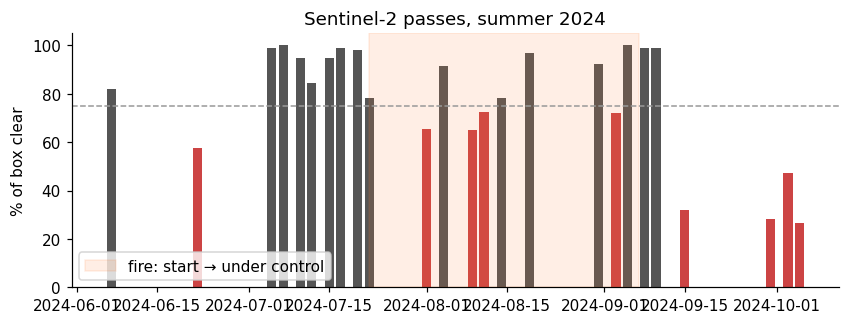

25 passes, 16 at least 75% clear


In [59]:
import matplotlib.pyplot as plt

plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})

# drop the pass that only clips the box, then plot how clear each one is
passes = passes[passes.covers_pct > 50].reset_index(drop=True)

fig, ax = plt.subplots(figsize=(9, 3))
ax.bar(passes.date, passes.clear_pct, width=1.6, color=np.where(passes.clear_pct >= 75, "#555", "#c44"))
ax.axvspan(FIRE_START, UNDER_CONTROL, color="#ff7a2f", alpha=.12, label="fire: start → under control")
ax.axhline(75, ls="--", c="#999", lw=1)
ax.set_ylabel("% of box clear"); ax.set_title("Sentinel-2 passes, summer 2024"); ax.legend(loc="lower left")
plt.show()
print(f"{len(passes)} passes, {(passes.clear_pct >= 75).sum()} at least 75% clear")

Plenty of clear passes either side of the fire. Three sets are picked from this:

- **Before**: six clear passes from 5 to 20 July, close to the fire so the vegetation is at the same stage of summer

- **After**: four clear passes from 19 August to 10 September. Earlier August passes are partly under smoke

- **Timeline** for the app: the clearest passes, plus 22 July (the morning before the fire started) and 1 August (the first look after, partly smoky)

In [60]:
PRE = ["2024-07-05_0", "2024-07-07_0", "2024-07-10_0", "2024-07-15_0", "2024-07-17_0", "2024-07-20_0"]
POST = ["2024-08-19_0", "2024-09-05_0", "2024-09-08_0", "2024-09-10_1"]
TIMELINE = ["2024-07-07_0", "2024-07-20_0", "2024-07-22_0", "2024-08-01_0", "2024-08-04_0",
            "2024-08-19_0", "2024-08-31_0", "2024-09-05_0", "2024-09-10_1"]

# check every chosen pass is in the cache
missing = [n for n in PRE + POST + TIMELINE if n not in names]
missing or "all chosen passes cached"

'all chosen passes cached'

<br/>

Section 1 leaves us with every pass cached on one grid, and the before, after and timeline passes picked out. Next is section 2: what the fire looks like in them

<br/>
<br/>

### 2. What the fire looks like from orbit

In **natural colour** (red, green, blue) the burn shows as a dark brown smear. A **shortwave-infrared composite** (SWIR, NIR and red shown as red, green and blue) makes it much clearer: living forest is green, burned ground is rust red, rock is pink, snow and ice cyan, water black

Both use the same colour stretch from the 20 July pass, so the dates compare fairly

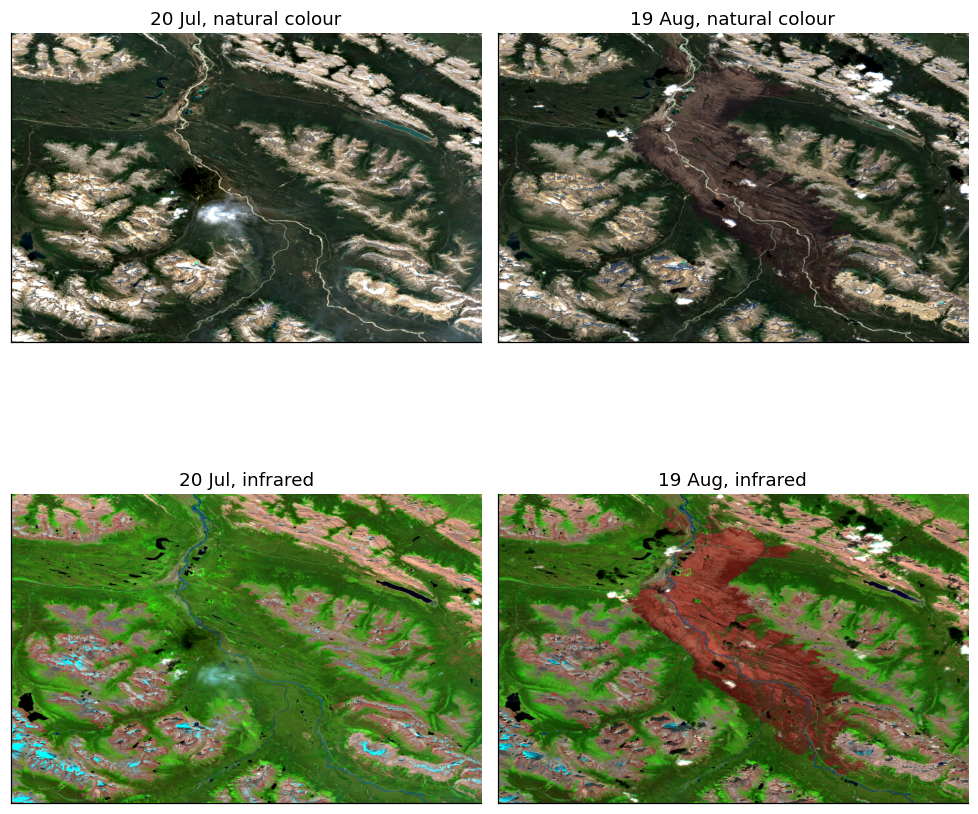

In [61]:
# function to turn three bands into a viewable image
def stretch(rgb, lo, hi, gamma=0.72):
    """
    Scale reflectance into 0 to 255 for display

    Args:
        rgb: Array of shape (rows, cols, 3)
        lo: Value shown as black
        hi: Value shown as white
        gamma: Below 1 brightens the darker values

    Returns:
        uint8 image
    """
    x = np.clip((rgb.astype(np.float32) - lo) / (hi - lo), 0, 1) ** gamma
    return (x * 255).astype(np.uint8)

# function to build a natural-colour or infrared image of one pass
def composite(d, bands, lohi):
    return stretch(np.dstack([d[b] for b in bands]), *lohi)

pre, post = load("2024-07-20_0"), load("2024-08-19_0")
TC = tuple(float(np.percentile(np.dstack([pre["red"], pre["green"], pre["blue"]]), p)) for p in (1, 97.5))
IR = tuple(float(np.percentile(np.dstack([pre["swir22"], pre["nir"], pre["red"]]), p)) for p in (1, 99.5))

# before and after, in natural colour and infrared
fig, axs = plt.subplots(2, 2, figsize=(9, 9.6))
for ax, d, bands, lohi, title in [
        (axs[0, 0], pre, ("red", "green", "blue"), TC, "20 Jul, natural colour"),
        (axs[0, 1], post, ("red", "green", "blue"), TC, "19 Aug, natural colour"),
        (axs[1, 0], pre, ("swir22", "nir", "red"), IR, "20 Jul, infrared"),
        (axs[1, 1], post, ("swir22", "nir", "red"), IR, "19 Aug, infrared")]:
    ax.imshow(composite(d, bands, lohi), extent=EXTENT)
    ax.set_title(title); ax.set_xticks([]); ax.set_yticks([])
plt.tight_layout(); plt.show()

**Reading the images**

- In natural colour (top), the burn is a dark band down the middle of the valley, from just south of Jasper to past Athabasca Falls

- In infrared (bottom), the same area turns from green to rust red, with sharp edges where the fire stopped against rock or rivers

- A small cloud sits over the middle of the 20 July image, which is why passes are combined in section 3 rather than using just one

<br/>

Section 2 shows the burn clearly in infrared. Next is section 3: measuring it

<br/>
<br/>

### 3. Measuring burn: the Normalized Burn Ratio

The **Normalized Burn Ratio (NBR)** compares near-infrared and shortwave infrared ([NBR](https://www.earthdatascience.org/courses/earth-analytics/multispectral-remote-sensing-modis/normalized-burn-index-dNBR/)):

$$\text{NBR} = \frac{\text{NIR} - \text{SWIR}}{\text{NIR} + \text{SWIR}}$$

Healthy forest has high NBR, burned ground low or negative. Before minus after gives **dNBR** (difference NBR), where a high value means a big loss of vegetation

The plan:

- **Before**: the median NBR of each pixel over the six clear passes before the fire, with cloudy pixels left out

- **After**: the same over the four clear passes after

- **Change**: before minus after (dNBR)

The median of several passes means one stray cloud or shadow on a single date doesn't show up as change

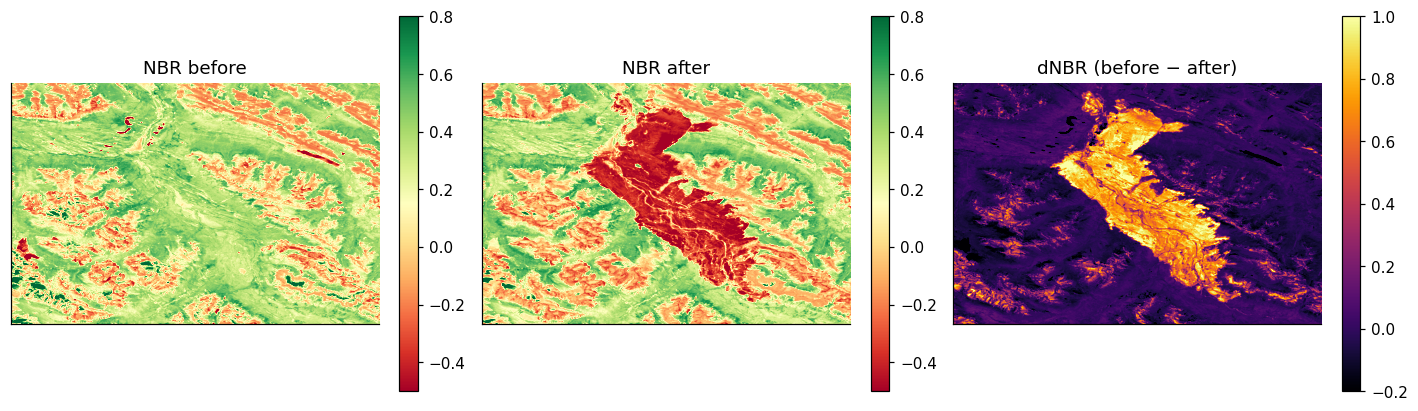

In [62]:
# function to work out NBR for one pass, leaving out pixels that aren't clear
def nbr(d):
    """
    Normalized Burn Ratio of one pass

    Args:
        d: Bands of one pass, from load()

    Returns:
        2D float array, NaN where the pixel isn't clear
    """
    nir, swir = d["nir"].astype(np.float32), d["swir22"].astype(np.float32)
    with np.errstate(invalid="ignore", divide="ignore"):
        value = (nir - swir) / (nir + swir)
    return np.where(clear_mask(d["scl"]), value, np.nan)

# before, after and the change
pre_nbr = np.nanmedian(np.stack([nbr(load(p)) for p in PRE]), axis=0)
post_nbr = np.nanmedian(np.stack([nbr(load(p)) for p in POST]), axis=0)
dnbr = pre_nbr - post_nbr

fig, axs = plt.subplots(1, 3, figsize=(13, 4.6))
for ax, layer, title, cmap, (lo, hi) in [(axs[0], pre_nbr, "NBR before", "RdYlGn", (-0.5, 0.8)),
                                         (axs[1], post_nbr, "NBR after", "RdYlGn", (-0.5, 0.8)),
                                         (axs[2], dnbr, "dNBR (before − after)", "inferno", (-0.2, 1.0))]:
    im = ax.imshow(layer, extent=EXTENT, cmap=cmap, vmin=lo, vmax=hi)
    ax.set_title(title); ax.set_xticks([]); ax.set_yticks([]); plt.colorbar(im, ax=ax, fraction=.046)
plt.tight_layout(); plt.show()

**Reading the three maps**

- **NBR before**: green over the forested valleys, red over rock and snow above the treeline, which has little vegetation to begin with

- **NBR after**: the valley floor south of Jasper turns red, the same as bare rock

- **dNBR**: bright where NBR dropped. The burn stands out as one connected shape down the valley. Some peaks are faintly bright too, from snow melting off between July and September

<br/>

**Choosing the threshold**

To turn dNBR into "burned" or "not burned", it needs a cut-off. The standard **FIREMON** severity breaks (Key & Benson, USDA Forest Service) are ([FIREMON](https://www.fs.usda.gov/rm/pubs_series/rmrs/gtr/rmrs_gtr164.pdf)):

- **0.10 to 0.27**: low severity

- **0.27 to 0.44**: moderate-low

- **0.44 to 0.66**: moderate-high

- **above 0.66**: high severity

Check where they fall against the values in the box

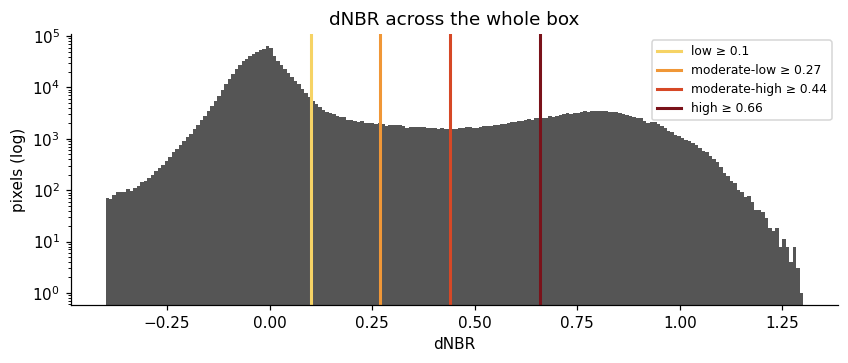

In [63]:
SEVERITY = [(0.10, "low", "#f6d365"), (0.27, "moderate-low", "#f09737"),
            (0.44, "moderate-high", "#d64826"), (0.66, "high", "#7a121a")]
BURNED = 0.27   # moderate severity and up counts as burned

# histogram of dNBR over the whole box, with the severity breaks
fig, ax = plt.subplots(figsize=(9, 3.2))
ax.hist(dnbr[np.isfinite(dnbr)], bins=200, range=(-0.4, 1.3), color="#555")
for lo, label, colour in SEVERITY:
    ax.axvline(lo, color=colour, lw=2, label=f"{label} ≥ {lo}")
ax.set_yscale("log"); ax.set_xlabel("dNBR"); ax.set_ylabel("pixels (log)"); ax.legend(fontsize=8)
ax.set_title("dNBR across the whole box")
plt.show()

- A big peak around **0** (ground that didn't change) and a second, smaller hump between about **0.5 and 1.0** (burned forest)

- **0.27** sits in the dip between them, so it separates the two well and is used as the cut-off for burned

Section 3 gives a burn map and a cut-off. Next is section 4: checking it against an independent record

<br/>

<br/>
<br/>

### 4. How much burned? Checking against the official perimeter

Natural Resources Canada's wildfire information system (**CWFIS**) publishes the **National Burned Area Composite (NBAC)**: the official mapped perimeter of every fire in Canada each year ([NBAC](https://cwfis.cfs.nrcan.gc.ca/datamart/metadata/nbac)). It's made independently of this analysis, so if the satellite measure is any good, the area above the threshold should land close to NBAC's figure and sit inside its outline

In [64]:
import urllib.request

# function to download a file once and reuse it after
def download(url, dest):
    """
    Download a file to data_raw/ unless it's already there

    Args:
        url: File to download
        dest: Where to save it

    Returns:
        Path to the file
    """
    if not dest.exists():
        print("downloading", url)
        urllib.request.urlretrieve(url, dest)
    return dest

nbac_zip = download("https://cwfis.cfs.nrcan.gc.ca/downloads/nbac/NBAC_2024_20260513.zip", DATA / "nbac_2024.zip")

In [65]:
import zipfile

import shapefile                     # pyshp
from pyproj import Transformer
from shapely import prepare, transform
from shapely.geometry import box, shape

# unzip the NBAC shapefile, it's in a Canada-wide projection, so set up the move to lon/lat
with zipfile.ZipFile(nbac_zip) as z:
    z.extractall(DATA / "nbac")
shp = next((DATA / "nbac").glob("*.shp")).with_suffix("")
to_lonlat = Transformer.from_crs(shp.with_suffix(".prj").read_text(), "EPSG:4326", always_xy=True)
to_lonlat_xy = lambda xy: np.column_stack(to_lonlat.transform(xy[:, 0], xy[:, 1]))

# keep the biggest fire that touches the box, checking each fire's bounding box first since that's much cheaper
fires = []
for record in shapefile.Reader(str(shp)).iterShapeRecords():
    if not transform(box(*record.shape.bbox), to_lonlat_xy).intersects(box(*AOI)):
        continue
    outline = transform(shape(record.shape.__geo_interface__), to_lonlat_xy)
    if outline.intersects(box(*AOI)):
        fires.append({**record.record.as_dict(), "outline": outline})

fires = pd.DataFrame(fires).sort_values("POLY_HA", ascending=False)
fires[["NFIREID", "FIRECAUS", "HS_SDATE", "HS_EDATE", "POLY_HA", "ADMIN_NAME"]]

,NFIREID,FIRECAUS,HS_SDATE,HS_EDATE,POLY_HA,ADMIN_NAME
0,451.0,Natural,2024-07-23,2024-09-07,31644.597903,PC


Useful:

- The first row is the Jasper fire, about **31,600 ha** (316 km²), first detected on 23 July (UTC, so the evening of 22 July locally)

- `PC` in `ADMIN_NAME` is Parks Canada, and the two tiny fires below it are separate and too small to matter

In [66]:
# the Jasper fire's outline, used from here on
peri = fires.iloc[0].outline
NBAC_KM2 = fires.iloc[0].POLY_HA / 100
prepare(peri)   # makes the many point-in-outline checks later much faster

The outline is turned into a mask on the same grid, plus a version with a small buffer (about 300 m) since the edges of the two won't match exactly

In [67]:
from rasterio.features import rasterize

# the NBAC outline as masks on the analysis grid
GRID_TRANSFORM = from_bounds(*AOI, GRID, GRID)
in_nbac = rasterize([peri], out_shape=(GRID, GRID), transform=GRID_TRANSFORM).astype(bool)
near_nbac = rasterize([peri.buffer(0.004)], out_shape=(GRID, GRID), transform=GRID_TRANSFORM).astype(bool)
burned = np.nan_to_num(dnbr) > BURNED

# compare the burned area with the official one
pd.Series({
    "burned inside the perimeter (km²)": round((burned & near_nbac).sum() * PX_KM2),
    "official NBAC area (km²)": round(NBAC_KM2),
    "share of the official area": f"{(burned & near_nbac).sum() * PX_KM2 / NBAC_KM2:.0%}",
    "overlap (intersection / union)": round((burned & in_nbac).sum() / (burned & near_nbac | in_nbac).sum(), 2),
    "burned pixels outside the perimeter (km²)": round((burned & ~near_nbac).sum() * PX_KM2),
}).to_frame("value")

,value
burned inside the perimeter (km²),302
official NBAC area (km²),316
share of the official area,96%
overlap (intersection / union),0.93
burned pixels outside the perimeter (km²),83


- **302 km²** against **316 km²**, about **96%** of the official area, with an overlap of **0.93**

- The pixels flagged outside the perimeter are mostly snow melting off the peaks, rivers and shadows changing. The index reads any loss of green as burn, so the severity map for the app is clipped to the official perimeter

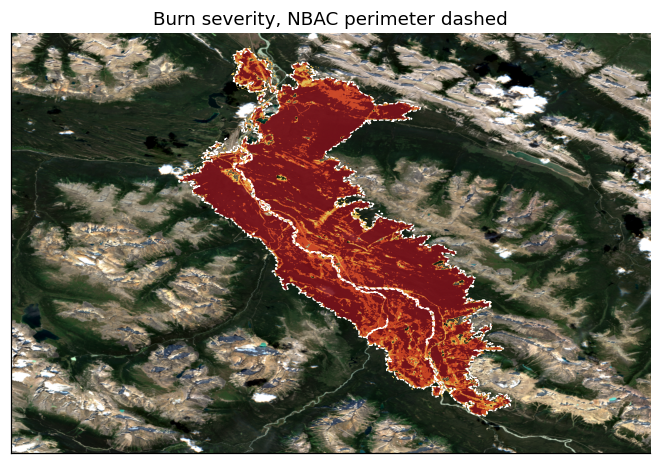

,km²,share
low,22.5,7%
moderate-low,25.8,8%
moderate-high,66.5,20%
high,210.0,65%


In [68]:
from matplotlib.colors import to_rgb

# severity classes inside the perimeter, over the 19 August photo, with the NBAC outline dashed
severity = np.zeros((GRID, GRID, 4))
areas = {}
for i, (lo, label, colour) in enumerate(SEVERITY):
    hi = SEVERITY[i + 1][0] if i + 1 < len(SEVERITY) else 9
    in_class = near_nbac & (dnbr >= lo) & (dnbr < hi)
    severity[in_class] = (*to_rgb(colour), .9)
    areas[label] = round(in_class.sum() * PX_KM2, 1)

fig, ax = plt.subplots(figsize=(7.5, 8))
ax.imshow(composite(post, ("red", "green", "blue"), TC), extent=EXTENT)
ax.imshow(severity, extent=EXTENT)
for part in (peri.geoms if peri.geom_type == "MultiPolygon" else [peri]):
    ax.plot(*part.exterior.xy, color="w", lw=.8, ls="--")
ax.set_title("Burn severity, NBAC perimeter dashed"); ax.set_xticks([]); ax.set_yticks([])
plt.show()

pd.Series(areas, name="km²").to_frame().assign(share=lambda t: (t["km²"] / t["km²"].sum()).map("{:.0%}".format))

- About two thirds of the burned area (**210 km²**) is **high severity**, where the canopy was killed outright

- The low and moderate classes sit mostly around the edges and along rivers, where the fire was patchier

Section 4 shows the satellite measure holds up against the official record. Next is section 5: when the burning happened

<br/>

<br/>
<br/>

### 5. Burned area through the summer

The same measure applied to each timeline pass on its own shows when the change happened. A cloudy pass only sees part of the perimeter, so its burned area is scaled up by how much of the perimeter it could see

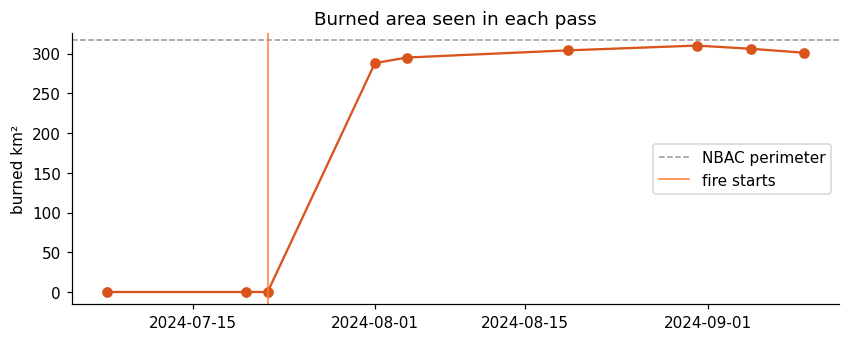

,date,perimeter_seen,burned_km2
0,2024-07-07,1.00,0
1,2024-07-20,0.93,0
2,2024-07-22,0.87,0
3,2024-08-01,0.69,288
4,2024-08-04,0.98,295
5,2024-08-19,0.97,304
6,2024-08-31,0.98,310
7,2024-09-05,1.00,306
8,2024-09-10,0.97,301


In [69]:
# burned area seen by each timeline pass, against the median before the fire
rows = []
for name in TIMELINE:
    change = pre_nbr - nbr(load(name))
    seen = np.isfinite(change) & near_nbac
    seen_share = seen.sum() / near_nbac.sum()
    rows.append({"date": pd.Timestamp(name[:10]), "perimeter_seen": round(seen_share, 2),
                 "burned_km2": round((seen & (change > BURNED)).sum() / seen_share * PX_KM2)})
over_time = pd.DataFrame(rows)

fig, ax = plt.subplots(figsize=(9, 3.2))
ax.plot(over_time.date, over_time.burned_km2, "o-", color="#d9541c")
ax.axhline(NBAC_KM2, ls="--", c="#999", lw=1, label="NBAC perimeter")
ax.axvline(FIRE_START, c="#ff7a2f", lw=1, label="fire starts")
ax.set_ylabel("burned km²"); ax.legend(loc="center right"); ax.set_title("Burned area seen in each pass")
plt.show()
over_time

- **0 km²** up to and including the morning of 22 July, then **288 km²** on 1 August, already most of the final figure

- The rest creeps up to just over 300 km² by late August, as the fire was held and then brought under control on 7 September

- So the fire did most of its damage in its first days, which is why section 6 focuses on 22 to 24 July

<br/>
<br/>

### 6. How fast it ran: satellite heat detections

CWFIS also publishes **hotspots**: points where a passing satellite saw an unusually hot pixel, with the time it was seen ([hotspots](https://cwfis.cfs.nrcan.gc.ca/downloads/hotspots/)). They only exist when a satellite is overhead, so they come in bursts, but they show where the fire was active at each overpass

The hotspot file covers all of Canada for the whole year, so keep only the rows over the box in July and August. Times are in UTC, converted to local time (MDT, UTC−6)

In [70]:
import csv
import io
from datetime import timedelta

hotspots_zip = download("https://cwfis.cfs.nrcan.gc.ca/downloads/hotspots/archive/2024_hotspots.zip", DATA / "hotspots_2024.zip")

# hotspots over the box in July and August, in local time
rows = []
with zipfile.ZipFile(hotspots_zip) as z:
    with z.open(next(f for f in z.namelist() if f.endswith(".csv"))) as f:
        for r in csv.DictReader(io.TextIOWrapper(f, "utf-8")):
            lon, lat = float(r["lon"]), float(r["lat"])
            if west < lon < east and south < lat < north and r["rep_date"][:7] in ("2024-07", "2024-08"):
                rows.append({"time": datetime.fromisoformat(r["rep_date"]) - timedelta(hours=6), "lon": lon, "lat": lat,
                             "sensor": r["sensor"], "frp": float(r["frp"] or 0)})
hotspots = pd.DataFrame(rows).sort_values("time").reset_index(drop=True)

# how many detections each day
hotspots.groupby(hotspots.time.dt.date).size().rename("detections").to_frame()

,detections
time,
2024-07-22,54
2024-07-23,1516
2024-07-24,1357
2024-07-31,7
2024-08-01,83
2024-08-02,332
2024-08-03,140
2024-08-04,6
2024-08-11,2


- Almost all the detections are on **22 to 24 July**, the first two days of the fire

- Then only a few dozen at a time, mostly early August. Smoke and cloud hide the fire from the sensors, and a burned-out area stops showing up as hot

- `frp` (fire radiative power) is how much heat the pixel gives off, in megawatts

**During the run**

Keep the hotspots within about 2 km of the perimeter (so unrelated fires in the box drop out) from 22 to 25 July

In [71]:
from shapely import contains_xy

# hotspots near the perimeter during the first days
zone = peri.buffer(0.02)
prepare(zone)
run = hotspots[(hotspots.time >= datetime(2024, 7, 22, 12)) & (hotspots.time <= datetime(2024, 7, 26))
               & contains_xy(zone, hotspots.lon.values, hotspots.lat.values)].reset_index(drop=True)
run["side"] = np.where(run.lat >= JASPER[1], "north of town", "south of town")
print(f"{len(run):,} detections from {run.time.min():%d %b %H:%M} to {run.time.max():%d %b %H:%M}")

2,868 detections from 22 Jul 22:59 to 24 Jul 14:59


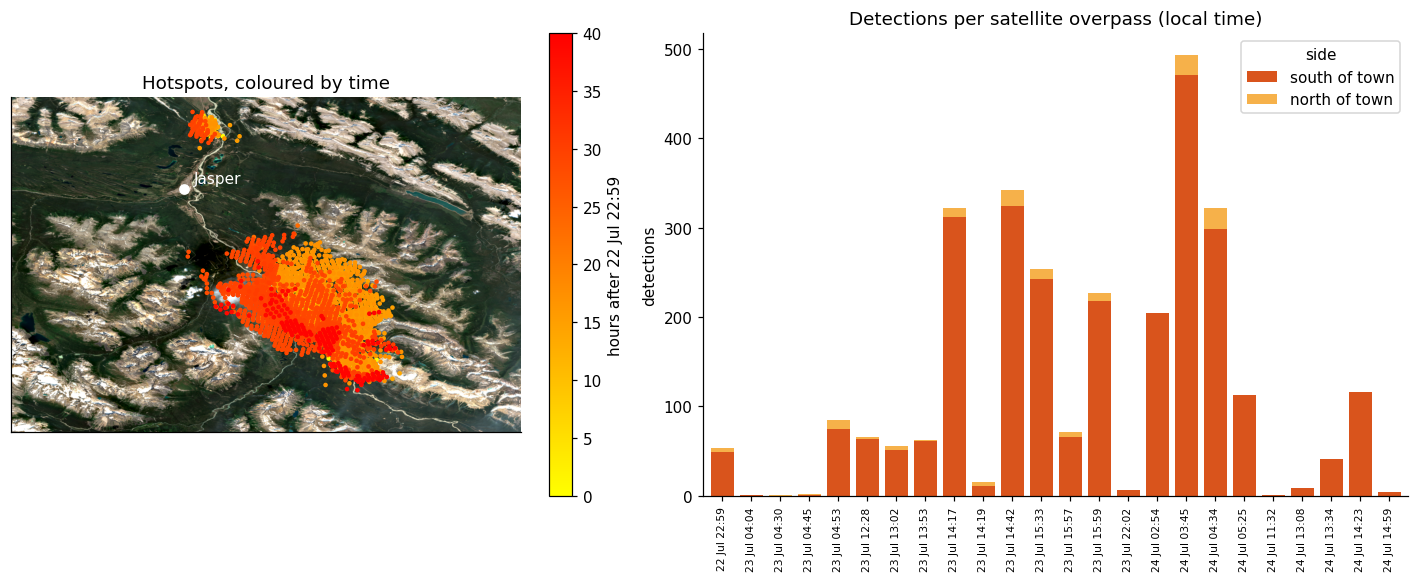

In [72]:
# where each detection was, coloured by time, and how many each satellite overpass saw on each side of town
hours = (run.time - run.time.min()).dt.total_seconds() / 3600
fig, axs = plt.subplots(1, 2, figsize=(13, 5.4), gridspec_kw={"width_ratios": [1, 1.25]})
axs[0].imshow(composite(pre, ("red", "green", "blue"), TC), extent=EXTENT)
points = axs[0].scatter(run.lon, run.lat, c=hours, cmap="autumn_r", s=4)
axs[0].plot(*JASPER, "wo", ms=6)
axs[0].annotate("Jasper", JASPER, color="w", xytext=(6, 4), textcoords="offset points")
axs[0].set_title("Hotspots, coloured by time"); axs[0].set_xticks([]); axs[0].set_yticks([])
plt.colorbar(points, ax=axs[0], fraction=.046, label=f"hours after {run.time.min():%d %b %H:%M}")

per_overpass = run.groupby(["time", "side"]).size().unstack(fill_value=0)
per_overpass.index = per_overpass.index.strftime("%d %b %H:%M")
per_overpass[["south of town", "north of town"]].plot.bar(stacked=True, ax=axs[1], color=["#d9541c", "#f6b14a"], width=.8)
axs[1].set_ylabel("detections"); axs[1].set_xlabel(""); axs[1].set_title("Detections per satellite overpass (local time)")
axs[1].tick_params(axis="x", labelsize=7)
plt.tight_layout(); plt.show()

- The first overpass after the fires started (22 July, about 11 pm) already has detections **north and south** of town, matching the reports of fires on both sides

- After that it's almost all the **southern fire**, spreading over most of the valley floor south of town within two days

- The last overpass in the data is **24 July at 3 pm**, a few hours before the fire reached the townsite (about 6 pm). Hotspots only exist when a satellite is overhead, so the moment it reached town isn't captured

<br/>

Section 6 shows how the fire spread in its first two days. Next is section 7: how close it came to the buildings in town

<br/>
<br/>

### 7. The townsite: from damage to exposure

At about 42 m per pixel the main grid is too coarse for single buildings, so read just the townsite again at Sentinel-2's full **10 m**, before (20 July) and after (5 September), and get the buildings from OpenStreetMap

The buildings come from **Geofabrik's Alberta extract**, a copy of all of OpenStreetMap for the province in one `.osm.pbf` file (about 345 MB), read locally with `pyosmium`. That avoids the public Overpass servers, which rate-limit and are often too busy to answer ([Geofabrik](https://download.geofabrik.de/north-america/canada.html), [pyosmium](https://docs.osmcode.org/pyosmium/latest/))

In [73]:
TOWN = (-118.110, 52.858, -118.040, 52.895)   # west, south, east, north
TOWN_W = round((TOWN[2] - TOWN[0]) * 111320 * math.cos(math.radians((TOWN[1] + TOWN[3]) / 2)) / 10)
TOWN_H = round((TOWN[3] - TOWN[1]) * 110570 / 10)
TOWN_PASSES = {"pre": "S2B_11UMU_20240720_0_L2A", "post": "S2B_11UMU_20240905_0_L2A"}

# read the townsite at 10 m for the two passes, once
town_file = DATA / "town.npz"
if not town_file.exists():
    town_items = {i.id: i for i in stac.search(collections=["sentinel-2-l2a"], ids=list(TOWN_PASSES.values())).items()}
    with rasterio.Env(GDAL_DISABLE_READDIR_ON_OPEN="EMPTY_DIR"):
        bands = {f"{tag}_{b}": read_band(town_items[i].assets[b].href, TOWN, TOWN_W, TOWN_H)
                 for tag, i in TOWN_PASSES.items() for b in ("red", "green", "blue", "nir", "swir22")}
    np.savez_compressed(town_file, **bands)
town = np.load(town_file)

# dNBR for the town at 10 m
def town_nbr(tag):
    nir, swir = town[f"{tag}_nir"].astype(np.float32), town[f"{tag}_swir22"].astype(np.float32)
    return (nir - swir) / np.maximum(nir + swir, 1)
town_dnbr = town_nbr("pre") - town_nbr("post")
print(f"town grid: {TOWN_W} x {TOWN_H} pixels at 10 m")

town grid: 470 x 409 pixels at 10 m


In [74]:
import json
import osmium

# OpenStreetMap for Alberta, from Geofabrik's province extract (rebuilt daily, read straight from the file)
# already have it from another project? point ALBERTA_PBF at that copy instead of downloading it again
ALBERTA_PBF = DATA / "alberta-latest.osm.pbf"
download("https://download.geofabrik.de/north-america/canada/alberta-latest.osm.pbf", ALBERTA_PBF)

# function to collect every building in the town box from the extract
class Buildings(osmium.SimpleHandler):
    """
    Reads an .osm.pbf file and keeps the centre of every building way inside a box

    Args:
        bbox: Bounding box (west, south, east, north) in degrees
    """
    def __init__(self, bbox):
        super().__init__()
        self.bbox, self.rows = bbox, []

    def way(self, w):
        if "building" not in w.tags:
            return
        try:
            lons, lats = [n.lon for n in w.nodes], [n.lat for n in w.nodes]
        except osmium.InvalidLocationError:   # a node outside the extract
            return
        # centre of the building's bounding box, the same point Overpass gives with "out center"
        lon, lat = (min(lons) + max(lons)) / 2, (min(lats) + max(lats)) / 2
        if self.bbox[0] <= lon <= self.bbox[2] and self.bbox[1] <= lat <= self.bbox[3]:
            self.rows.append({"id": w.id, "lon": lon, "lat": lat, "type": w.tags.get("building")})

# read the extract once (about 20 seconds for Alberta) and cache the town's buildings
osm_file = DATA / "osm_buildings.json"
if not osm_file.exists():
    reader = Buildings(TOWN)
    reader.apply_file(str(ALBERTA_PBF), locations=True)   # locations=True gives each node its coordinates
    osm_file.write_text(json.dumps(reader.rows))

buildings = pd.DataFrame(json.loads(osm_file.read_text()))
# the pixel each building sits in
buildings["col"] = ((buildings.lon - TOWN[0]) / (TOWN[2] - TOWN[0]) * TOWN_W).astype(int).clip(0, TOWN_W - 1)
buildings["row"] = ((TOWN[3] - buildings.lat) / (TOWN[3] - TOWN[1]) * TOWN_H).astype(int).clip(0, TOWN_H - 1)
print(len(buildings), "mapped buildings in and around the townsite")
buildings.type.value_counts().head(8).to_frame("buildings")

1127 mapped buildings in and around the townsite


,buildings
type,
yes,592
detached,206
cabin,70
house,40
static_caravan,38
semidetached_house,35
apartments,28
garage,26


**First try: dNBR at each building**

Read dNBR at the pixel each building sits in, and count the ones above the threshold

In [75]:
# dNBR right at each building
buildings["dnbr"] = town_dnbr[buildings.row, buildings.col]
pd.Series({"median dNBR at a building": round(buildings.dnbr.median(), 2),
           f"buildings above {BURNED}": int((buildings.dnbr > BURNED).sum()),
           "structures reported lost": 358}).to_frame("value")

,value
median dNBR at a building,-0.01
buildings above 0.27,2.00
structures reported lost,358.00


- Only **3** buildings come up as burned, against **358** reported lost

- NBR measures *vegetation*. A roof has almost no vegetation signal before the fire, and a burned lot has almost none after, so the index barely moves when a house burns. The strong signal is in the forest around the houses

**Second try: exposure**

Measure how far each building is from burned ground instead. Burned ground is dNBR above the threshold, with single stray pixels removed (a morphological opening). A **distance transform** then gives every pixel its distance in metres to the nearest burned pixel ([distance transform](https://docs.scipy.org/doc/scipy/reference/generated/scipy.ndimage.distance_transform_edt.html))

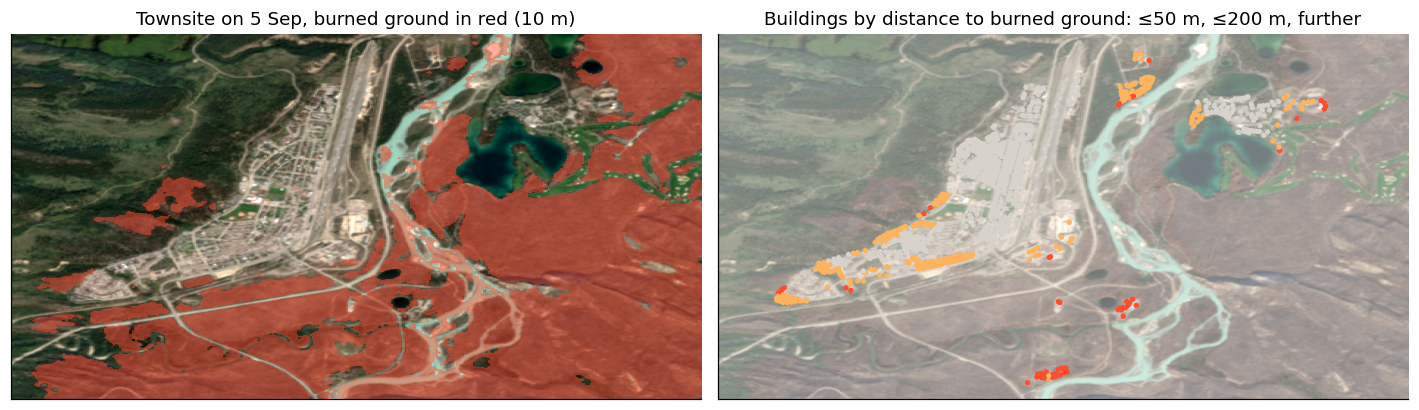

,buildings
within 0 m,2
within 50 m,61
within 100 m,126
within 200 m,365
within 500 m,822


In [76]:
from matplotlib.colors import ListedColormap
from scipy import ndimage

# burned ground in town, cleaned of stray pixels, and every pixel's distance to it in metres
scar = ndimage.binary_opening(town_dnbr > BURNED, iterations=2)
cell_x = (TOWN[2] - TOWN[0]) * 111320 * math.cos(math.radians((TOWN[1] + TOWN[3]) / 2)) / TOWN_W
cell_y = (TOWN[3] - TOWN[1]) * 110570 / TOWN_H
distance = ndimage.distance_transform_edt(~scar, sampling=(cell_y, cell_x))
buildings["dist_m"] = np.round(distance[buildings.row, buildings.col])

# the town after the fire with burned ground in red, and each building coloured by its distance
town_extent = [TOWN[0], TOWN[2], TOWN[1], TOWN[3]]
town_lohi = tuple(float(np.percentile(np.dstack([town["pre_red"], town["pre_green"], town["pre_blue"]]), p)) for p in (1, 99.5))
town_photo = stretch(np.dstack([town["post_red"], town["post_green"], town["post_blue"]]), *town_lohi)
colours = np.where(buildings.dist_m <= 50, "#ff4d2e", np.where(buildings.dist_m <= 200, "#ffb35c", "#d8d2cc"))

fig, axs = plt.subplots(1, 2, figsize=(13, 5.6))
axs[0].imshow(town_photo, extent=town_extent)
axs[0].imshow(np.ma.masked_where(~scar, scar), extent=town_extent, cmap=ListedColormap(["#ff4d2e"]), alpha=.45)
axs[0].set_title("Townsite on 5 Sep, burned ground in red (10 m)")
axs[1].imshow(town_photo, extent=town_extent, alpha=.55)
axs[1].scatter(buildings.lon, buildings.lat, c=colours, s=6)
axs[1].set_title("Buildings by distance to burned ground: ≤50 m, ≤200 m, further")
for ax in axs:
    ax.set_xticks([]); ax.set_yticks([])
plt.tight_layout(); plt.show()

pd.Series({f"within {d} m": int((buildings.dist_m <= d).sum()) for d in (0, 50, 100, 200, 500)}, name="buildings").to_frame()

- **64** buildings sit within 50 m of burned ground and **366** within 200 m

- The most exposed are on the **west and southwest edges** of town, where the forest runs right up to the houses, which is where the fire came in (embers from the Whistlers' slopes onto the southwest corner)

- This measures **exposure, not damage**: a house can burn from embers with no scorched forest next to it, and a house next to burned forest can survive

**Wrapping up**

- dNBR maps the burn to within 4% of the official area, with 0.93 overlap, and most of it is high severity

- Nearly all of it burned in the first days, with fires on both sides of town at the first overpass

- In town, the burn index can't see destroyed houses, but it does show which buildings were closest to burned ground

**Limits:** 10 to 42 m pixels, cloud and smoke gaps on some passes, OpenStreetMap building coverage, and hotspots only when a satellite is overhead